<a href="https://colab.research.google.com/github/sc-godela/ai-wardrobe-stylist/blob/main/notebooks/01_explore_dataset.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [1]:
!pip install -q datasets

In [3]:
from datasets import load_dataset

ds=load_dataset("owj0421/polyvore", split="data", streaming=True)
print(ds)

IterableDataset({
    features: ['item_id', 'image', 'url_name', 'title', 'description', 'category'],
    num_shards: 6
})


item_id:211990161
url_name:neck print chiffon plus size
title:
description:
category:tops


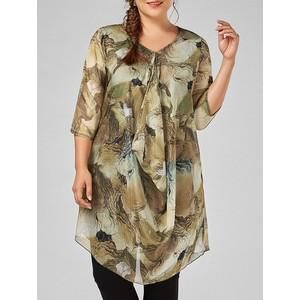

In [5]:
first=next(iter(ds))
for key, value in first.items():
  if key != "image":
    print(f"{key}:{value}")
first["image"]

In [14]:
from collections import Counter

sample = list(ds.take(2000))
counts = Counter(item["category"] for item in sample)
for category, n in counts.most_common(15):
  print(f"{n:5d} {category}")

  362 shoes
  342 jewellery
  305 bags
  277 tops
  231 bottoms
  150 outerwear
  135 all-body
   70 sunglasses
   46 accessories
   45 hats
   37 scarves


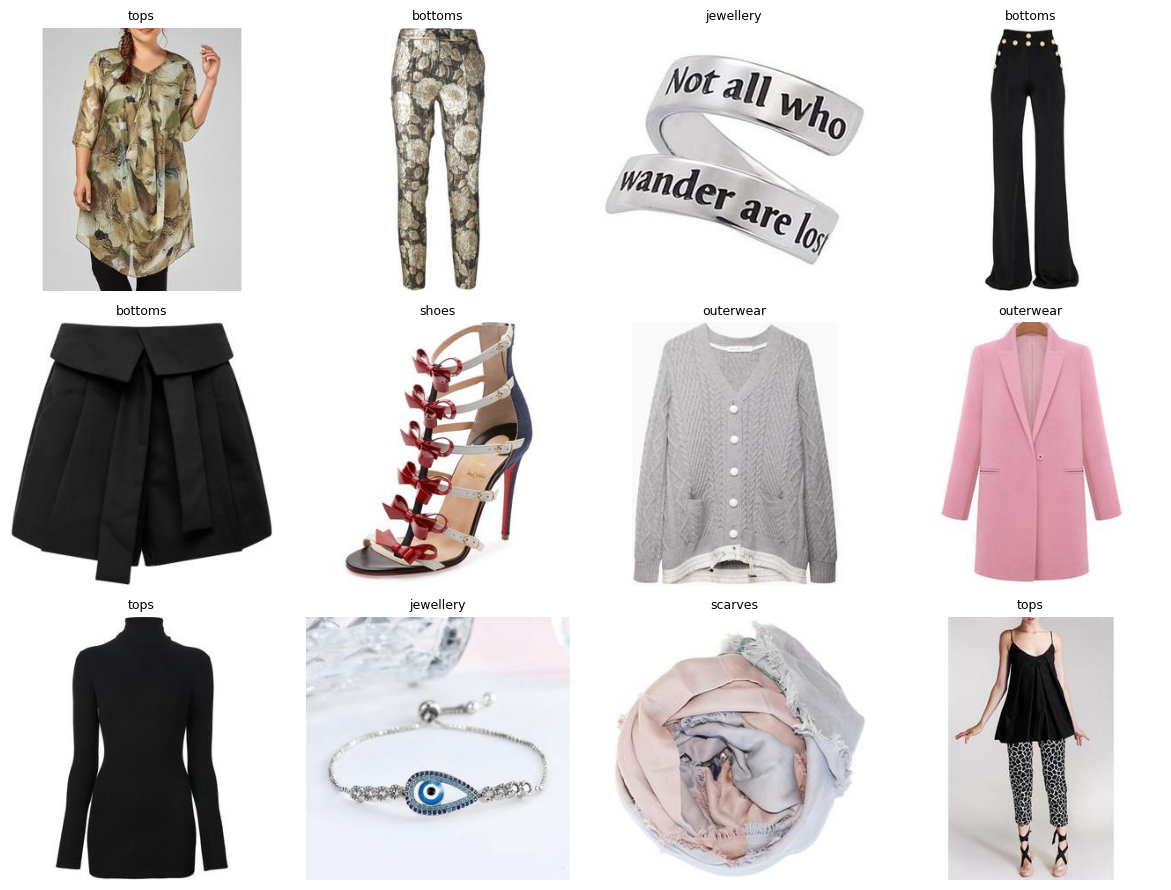

In [15]:
import matplotlib.pyplot as plt

fig, axes = plt.subplots(3, 4, figsize=(12, 9))
for ax, item in zip(axes.flat, sample[:12]):
    ax.imshow(item["image"])
    ax.set_title(item["category"][:20], fontsize=9)
    ax.axis("off")
plt.tight_layout()
plt.show()

In [16]:
import re

titles = [item["title"].lower() for item in sample]

patterns = {
    "women": r"\bwomen",
    "men":   r"\bmen(?:'s|s)?\b",
    "unisex": r"\bunisex\b",
    "kids":  r"\b(?:kids|girls|boys|baby)\b",
}

for label, pattern in patterns.items():
    n = sum(bool(re.search(pattern, t)) for t in titles)
    print(f"{label:7s} {n:4d} of {len(titles)}  ({n / len(titles):.1%})")

women     48 of 2000  (2.4%)
men        1 of 2000  (0.1%)
unisex     0 of 2000  (0.0%)
kids       1 of 2000  (0.1%)


## Conclusion
**Is Polyvore suitable for a menswear project? No.**

Evidence from a 2,000-item sample:
- **Keyword check:** 97.5% of titles name no gender, but among those
  that do, 48 mention women vs. 1 men (~48:1).
- **Visual check:** the sampled images are overwhelmingly womenswear.
- **Literature:** the ASOS dataset paper (Bettaney et al., 2020)
  describes Polyvore Outfits as entirely womenswear.

**Limitation:** titles rarely state gender, so the keyword check alone
is weak; the conclusion rests on all three signals together.

**Decision:** switch to the ASOS Outfits dataset, which includes
272k menswear outfits → see `02_asos_data_check.ipynb`.